# API 12: Checkpoint, save & load model

A KANNetwork keeps no versions of itself (xKAN has no auto_save, history or rewind). To get a state back after you change the model (fit, prune, ...), save a checkpoint with `xkan.io.save_checkpoint(model, path)` and load it with `xkan.io.load_checkpoint(path)`. This notebook names the checkpoints in the folder `model` after pykan's versions 'a.b': a is the round, b the version within the round.

Save the initialized model as version 0.0.

cuda


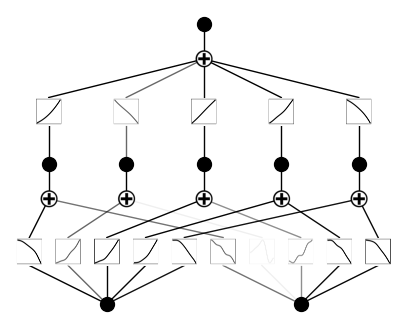

In [1]:
import torch
from xkan import KANNetwork, create_dataset, fit
from xkan.interp import prune
from xkan.io import load_checkpoint, save_checkpoint
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

f = lambda x: torch.exp(torch.sin(torch.pi*x[:,[0]]) + x[:,[1]]**2)
train, test = create_dataset(f, n_var=2, device=device)
model = KANNetwork([2,5,1], grid=5, k=3, seed=1, device=device)
save_checkpoint(model, './model/0.0')
plot(model, train['x']);

A checkpoint is a directory with the construction options and symbolic functions (`config.json`) and the parameters (`state.pt`).

In [2]:
import os
sorted(os.listdir('./model/0.0'))

['config.json', 'state.pt']

After fitting, save version 0.1.

train RMSE 0.051587598645370374 test RMSE 0.052629512265236454


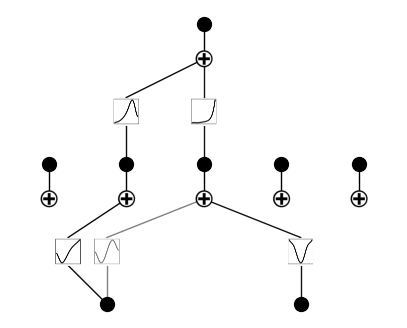

In [3]:
history = fit(model, train, test, steps=20, lamb=0.01)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)
save_checkpoint(model, './model/0.1')
plot(model, train['x']);

After pruning, save version 0.2.

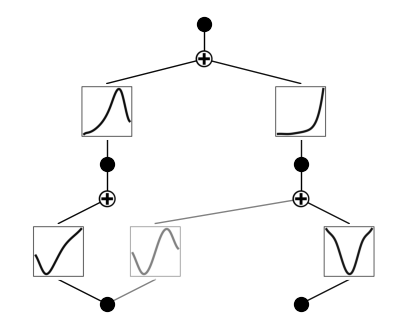

In [4]:
model = prune(model, train['x'])
save_checkpoint(model, './model/0.2')
plot(model, train['x']);

To go back to version 0.1, load its checkpoint (`load_checkpoint` maps the model to the CPU unless you pass `map_location`). The loaded model starts a new round as version 1.1.

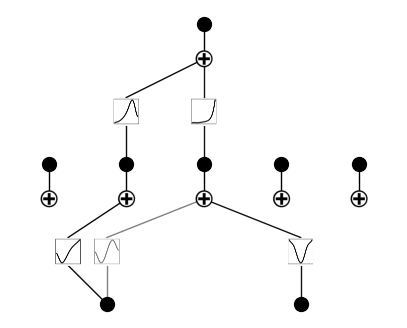

In [5]:
# revert to version 0.1 (the same whether continuing or starting from scratch)
model = load_checkpoint('./model/0.1', map_location=device)
plot(model, train['x']);

After more changes to version 1.1, save the result as version 1.2.

train RMSE 0.04236499394234315 test RMSE 0.04683416047833314


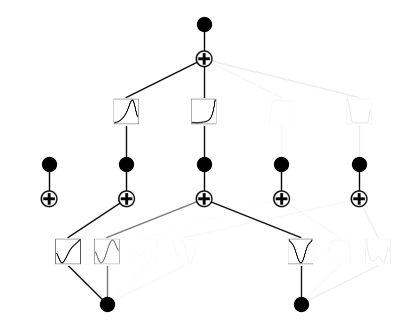

In [6]:
history = fit(model, train, test, steps=2)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)
save_checkpoint(model, './model/1.2')
plot(model, train['x']);